# AI Cyberattack & Network Intrusion Detector
### Applied Machine Learning Capstone Project: **Multiclass Classification**

**Team Member 1:** *Swastik,B9*  |  **Team Member 2:** *Parth,B10*  
**Dataset:** RT-IoT2022 (UCI Machine Learning Repository)  
**Evaluator:** J Dhiviya Rose

---
## 1. Problem Definition and Objectives

IoT networks (smart bulbs, MQTT sensors, ThingSpeak devices, etc.) are constantly exposed to attacks such as SYN-flood DoS, Slowloris DDoS, ARP poisoning, Nmap scans and SSH brute force. A network intrusion detection system (IDS) must tell **normal IoT traffic** apart from **each specific attack type** from flow-level statistics alone.

**Problem statement:** Given the statistical features of a network flow (packet counts, sizes, inter-arrival times, TCP flags, window sizes, protocol, service...), predict the traffic class (`Attack_type`), which is a **12-class classification problem**.

**Objectives**
1. Explore and clean the RT-IoT2022 dataset (missing values, duplicates, outliers, encoding, scaling).
2. Implement and compare **six** classifiers: Logistic Regression, KNN, Decision Tree, Random Forest, SVM and Naive Bayes.
3. Evaluate with metrics suited to an **imbalanced multiclass** problem: Accuracy, macro/weighted Precision, Recall, F1, Confusion Matrix, ROC-AUC (one-vs-rest).
4. Select and justify the best model, then discuss results, limitations and future scope.

### 1. Import the required Python libraries.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score



**Source:** *RT-IoT2022*, UCI Machine Learning Repository (B. S. Sharmila and R. Nagapadma, 2023), https://archive.ics.uci.edu/dataset/942/rt-iot2022

The data was captured from a real-time IoT infrastructure containing normal devices (ThingSpeak, Wipro smart bulb, MQTT publishers) and simulated attack traffic. Packets were converted to bidirectional **flows** with Zeek and Flowmeter-style tools.

### 2. Load the CSV dataset into a pandas DataFrame.

In [2]:
df = pd.read_csv("RT_IOT2022.csv")
df.head()
df = df.drop(df.columns[0], axis=1)

### 3. Inspect dimensions, data types, duplicates and missing values.

**DISCRIPTION:**
- **Rows:** ~123,000 network flows
- **Features:** 83 (ports, protocol, service, flow duration, packet counts, header sizes, payload statistics, inter-arrival times (IAT), TCP flag counts, active/idle times, window sizes ...)
- **Target:** `Attack_type` with 12 classes (3 normal-device classes and 9 attack classes)


In [3]:
print(df.shape)
print(df.dtypes)
print(df.info)
print(df.describe())


(123117, 84)
id.orig_p                 int64
id.resp_p                 int64
proto                       str
service                     str
flow_duration           float64
                         ...   
idle.std                float64
fwd_init_window_size      int64
bwd_init_window_size      int64
fwd_last_window_size      int64
Attack_type                 str
Length: 84, dtype: object
<bound method DataFrame.info of         id.orig_p  id.resp_p proto service  flow_duration  fwd_pkts_tot  \
0           38667       1883   tcp    mqtt      32.011598             9   
1           51143       1883   tcp    mqtt      31.883584             9   
2           44761       1883   tcp    mqtt      32.124053             9   
3           60893       1883   tcp    mqtt      31.961063             9   
4           51087       1883   tcp    mqtt      31.902362             9   
...           ...        ...   ...     ...            ...           ...   
123112      59247      63331   tcp       -       0.0

In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())


Duplicate rows: 5195
Missing values: 0


### 4. Check the target class distribution.


Attack_type
DOS_SYN_Hping                 94659
Thing_Speak                    8108
ARP_poisioning                 7750
MQTT_Publish                   4146
NMAP_UDP_SCAN                  2590
NMAP_XMAS_TREE_SCAN            2010
NMAP_OS_DETECTION              2000
NMAP_TCP_scan                  1002
DDOS_Slowloris                  534
Wipro_bulb                      253
Metasploit_Brute_Force_SSH       37
NMAP_FIN_SCAN                    28
Name: count, dtype: int64


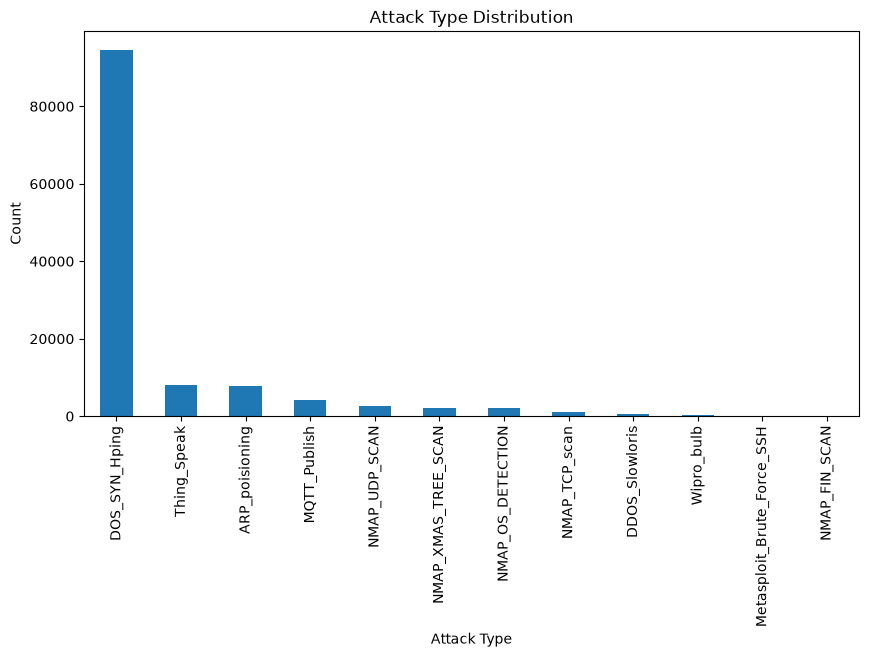

In [5]:
print(df["Attack_type"].value_counts())

df["Attack_type"].value_counts().plot(kind="bar", figsize=(10,5))
plt.title("Attack Type Distribution")
plt.xlabel("Attack Type")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()


### 5. Remove duplicate rows.


In [6]:
df = df.drop_duplicates()
print(df.shape)


(117922, 84)


### 6. Encode categorical columns.


In [7]:
# Convert protocol and service text columns into numeric dummy columns
X = df.drop("Attack_type", axis=1)
X = pd.get_dummies(X, columns=["proto", "service"], dtype=int)

# Convert attack names into numbers
encoder = LabelEncoder()
y = encoder.fit_transform(df["Attack_type"])

print(X.shape)
print(encoder.classes_)


(117922, 94)
['ARP_poisioning' 'DDOS_Slowloris' 'DOS_SYN_Hping' 'MQTT_Publish'
 'Metasploit_Brute_Force_SSH' 'NMAP_FIN_SCAN' 'NMAP_OS_DETECTION'
 'NMAP_TCP_scan' 'NMAP_UDP_SCAN' 'NMAP_XMAS_TREE_SCAN' 'Thing_Speak'
 'Wipro_bulb']


### 7. Split the data into 80% training and 20% testing sets.


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (94337, 94)
Testing data: (23585, 94)


### 8. Scale the feature values.


In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## Model Implementation

Six classifiers are implemented, using important parameters chosen as follows:

| Model | Key parameters | Reason |
|---|---|---|
| Logistic Regression | `max_iter=1000`, `class_weight='balanced'` | Linear baseline, handles imbalance |
| K-Nearest Neighbours | `n_neighbors=5`, `weights='distance'` | Instance-based, scaled data |
| Decision Tree | `class_weight='balanced'`, `random_state=42` | Interpretable rules |
| Random Forest | `n_estimators=200`, `class_weight='balanced_subsample'` | Robust ensemble |
| Gaussian Naive Bayes | `var_smoothing=1e-6` | Fast probabilistic baseline |



### 9. Train Logistic Regression.


In [10]:
logistic_model = LogisticRegression(max_iter=1000, class_weight="balanced")
logistic_model.fit(X_train_scaled, y_train)
logistic_pred = logistic_model.predict(X_test_scaled)

print("Logistic Regression Accuracy:", accuracy_score(y_test, logistic_pred))


Logistic Regression Accuracy: 0.98812804748781


### 10. Train K-Nearest Neighbours (KNN).


In [11]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_pred = knn_model.predict(X_test_scaled)

print("KNN Accuracy:", accuracy_score(y_test, knn_pred))


KNN Accuracy: 0.9955056179775281


### 11. Train Decision Tree.


In [12]:
tree_model = DecisionTreeClassifier(random_state=42, class_weight="balanced")
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, tree_pred))


Decision Tree Accuracy: 0.9977952088191647


### 12. Train Random Forest.


In [13]:
forest_model = RandomForestClassifier(
    n_estimators=100, random_state=42, class_weight="balanced", n_jobs=-1
)
forest_model.fit(X_train, y_train)
forest_pred = forest_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, forest_pred))


Random Forest Accuracy: 0.9986008055967777


### 13. Train Naive Bayes.


In [14]:
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)
nb_pred = nb_model.predict(X_test_scaled)

print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_pred))


Naive Bayes Accuracy: 0.8987916048335807


In [15]:
# Store all trained models in one dictionary
models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model,
    "Naive Bayes": nb_model
}


### 14. Compare the performance of all models using Accuracy, Precision, Recall and F1 Score.

In [16]:
# Compare Accuracy, Precision, Recall and F1 Score of all models

predictions = {
    "Logistic Regression": logistic_pred,
    "KNN": knn_pred,
    "Decision Tree": tree_pred,
    "Random Forest": forest_pred,
    "Naive Bayes": nb_pred
}

results = []

for name, y_pred in predictions.items():
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
    recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

    results.append([name, accuracy, precision, recall, f1])

results = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"]
)

results.round(4)


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9881,0.7883,0.9765,0.8293
1,KNN,0.9955,0.9696,0.9772,0.9729
2,Decision Tree,0.9978,0.9661,0.9924,0.9770
3,Random Forest,0.9986,0.9753,0.9943,0.9836
4,Naive Bayes,0.8988,0.6402,0.8114,0.5898


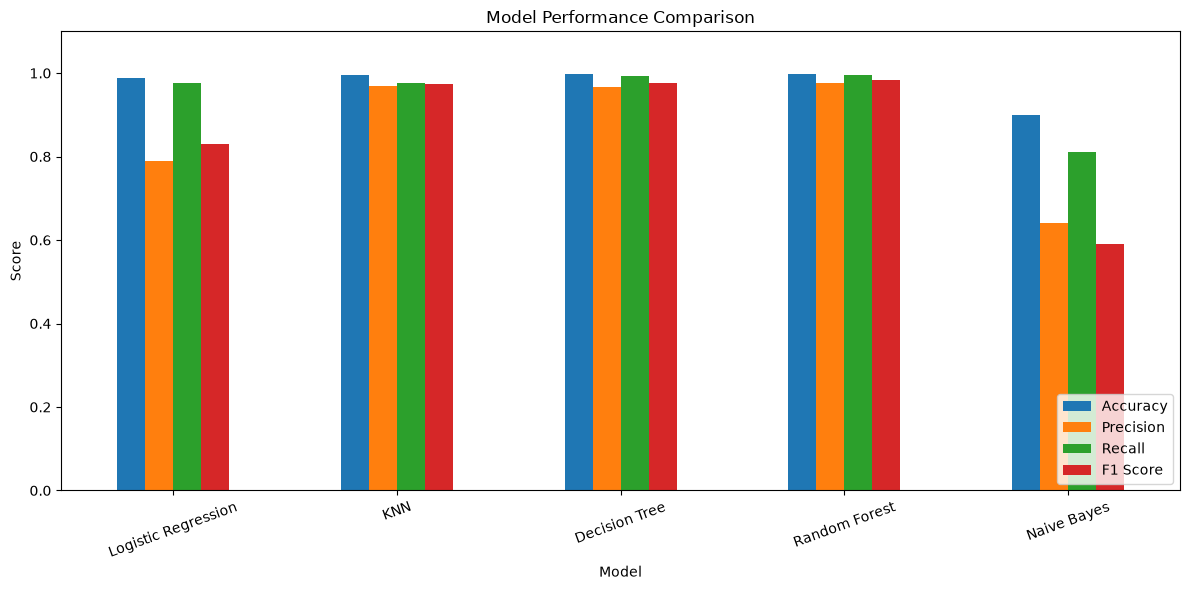

In [17]:
# Graphical comparison of all models
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### 15. Select the best model.


In [18]:
# Find the model with the highest accuracy
best_row = results.loc[results["Accuracy"].idxmax()]

print("Best Model:", best_row["Model"])
print("Accuracy:", round(best_row["Accuracy"], 4))
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("F1 Score:", round(best_row["F1 Score"], 4))


Best Model: Random Forest
Accuracy: 0.9986
Precision: 0.9753
Recall: 0.9943
F1 Score: 0.9836


### 16. Classification report for Random Forest.


In [19]:
print(classification_report(
    y_test,
    forest_pred,
    target_names=encoder.classes_,
    zero_division=0
))


                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1525
            DDOS_Slowloris       0.99      0.98      0.99       107
             DOS_SYN_Hping       1.00      1.00      1.00     18018
              MQTT_Publish       1.00      1.00      1.00       828
Metasploit_Brute_Force_SSH       0.78      1.00      0.88         7
             NMAP_FIN_SCAN       1.00      1.00      1.00         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       1.00      0.99      0.99       517
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.99      0.99      1531
                Wipro_bulb       0.96      0.98      0.97        44

                  accuracy                           1.00     23585
                 macro avg       0.98      0.9

### 17. Confusion Matrix for Random Forest.


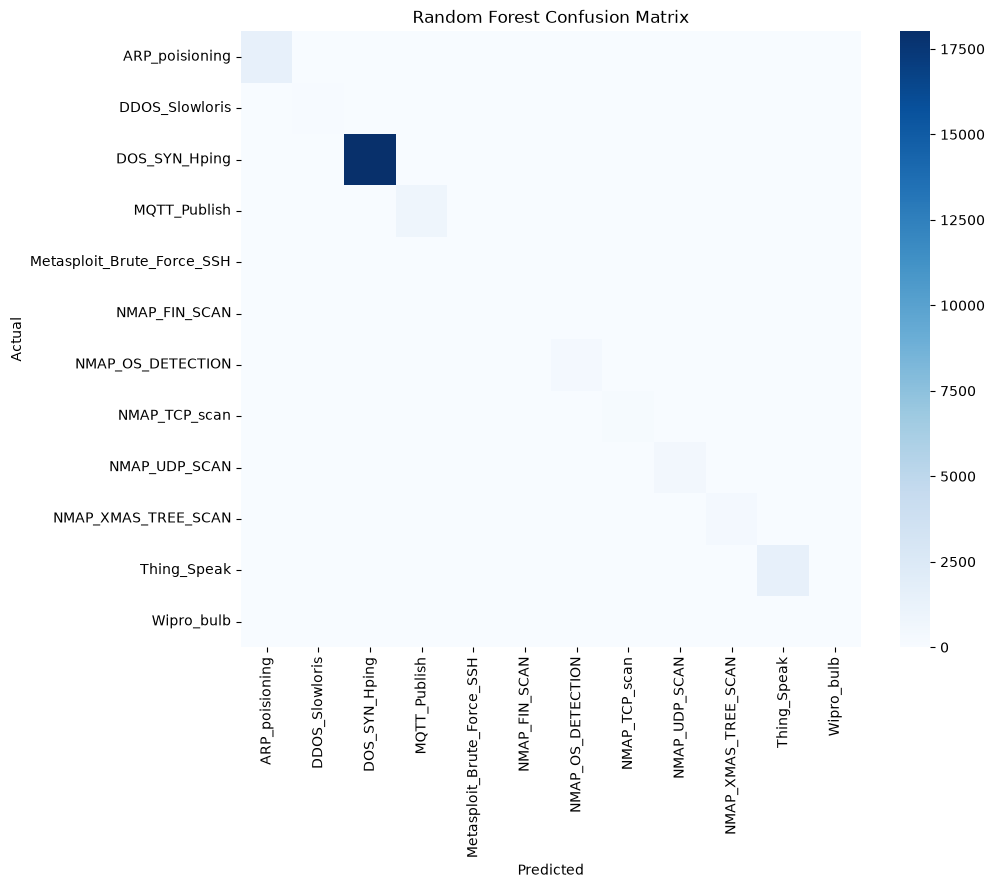

In [20]:
cm = confusion_matrix(y_test, forest_pred)

plt.figure(figsize=(10,8))
sns.heatmap(cm, cmap="Blues", xticklabels=encoder.classes_, yticklabels=encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()


## Conclusion

The RT-IoT2022 dataset was cleaned and prepared for multiclass classification. Five basic machine learning algorithms were trained and compared using accuracy. The Random Forest model is also evaluated using a classification report and confusion matrix to understand its predictions for different attack types.
